## Assignment 1: Data Profiling (EDA) Report
**Dataset:** Hotel Booking Demand  
**Team Name:** Group 10

| Member Name | Matric Number |
|---|---|
| NUR NAJWA BINTI MOHAMAD NADZRI | A221486 |
| AMIRA FARIZA BINTI SUHAIRI | A216295 |
| SHARMILA A/P K J VADIVAZAGAN | A216155 |
| THANA VITHYASSWARY A/P SANKAR | A216381 |

## 1. Scenario
The Hotel Booking Demand dataset contains booking records collected from both city hotels and resort hotels. It includes customer booking details such as hotel type, booking lead time, arrival dates, number of guests, room types, cancellation status, and average daily room rates. This dataset is appropriate for this assignment because it contains missing values in several columns (such as company, agent, country, and children), duplicate records, outliers in numerical attributes such as average daily rate (ADR) and lead time, and potential bias related to customer nationality and booking behaviour.

**Main Questions to Answer:**
- Which variables contain missing values and how should they be handled?
- Are there duplicate records that should be removed?
- Which numerical variables contain outliers?
- Are there any sensitive information or sampling bias that may influence future analysis?

## 2. Data Source
- **Dataset Name:** Hotel Booking Demand
- **Source:** Kaggle
- **URL:** https://www.kaggle.com/datasets/jessemostipak/hotel-booking-demand
- **How Obtained:** The dataset was downloaded from Kaggle as a CSV file and imported into Jupyter Notebook using Pandas to perform data profiling, detect data quality issues, and prepare the dataset for analysis.

## 3. Data Profiling and Issue Handling

### A. Missing Values
- **`company` (112,593 missing / 94.31%):** Imputed missing values with `0` (representing "Private / Non-Corporate Booking"). Dropping this column erases corporate signals, while dropping incomplete rows eliminates over 94% of data.
- **`agent` (16,340 missing / 13.69%):** Imputed missing values with `0` (representing "Direct Booking / No Agency").
- **`country` (488 missing / 0.41%):** Imputed missing entries with the placeholder `'Unknown'`.
- **`children` (4 missing / <0.01%):** Imputed missing entries with `0`.

### B. Outliers
- **`adr` (Average Daily Rate):** Contains an invalid negative value (`-$6.38`) and an extreme outlier (`$5,400.00`). Filtered out negative rates (`adr < 0`) and capped/dropped extreme entries (`adr > 1000`).
- **`lead_time`:** Extends up to 737 days. Retained as valid long-term reservations.

### C. Other Quality Issues
- **Duplicate Records:** Identified 31,994 duplicate rows (26.80%). Retained for initial profiling, but flagged for removal during customer behavior modeling.
- **Invalid Zero-Guest Transactions:** Removed 180 rows where `adults`, `children`, and `babies` all equaled `0`.
- **Inconsistent Categorical Values:** Mapped 1,169 `'Undefined'` values in `meal` to `'SC'` (Self-Catering).
- **Incorrect Data Types:** Cast `reservation_status_date` from `object` string to `datetime64[ns]`.

--- 1. DATASET SUCCESSFULLY LOADED ---
Original shape (Rows, Columns): (119390, 32)

--- 2. DATASET SUMMARY & INFORMATION ---
<class 'pandas.core.frame.DataFrame'>
RangeIndex: 119390 entries, 0 to 119389
Data columns (total 32 columns):
 #   Column                          Non-Null Count   Dtype  
---  ------                          --------------   -----  
 0   hotel                           119390 non-null  object 
 1   is_canceled                     119390 non-null  int64  
 2   lead_time                       119390 non-null  int64  
 3   arrival_date_year               119390 non-null  int64  
 4   arrival_date_month              119390 non-null  object 
 5   arrival_date_week_number        119390 non-null  int64  
 6   arrival_date_day_of_month       119390 non-null  int64  
 7   stays_in_weekend_nights         119390 non-null  int64  
 8   stays_in_week_nights            119390 non-null  int64  
 9   adults                          119390 non-null  int64  
 10  children      

/tmp/ipykernel_787/3245692372.py:92: UserWarning: set_ticklabels() should only be used with a fixed number of ticks, i.e. after set_ticks() or using a FixedLocator.
  axes[0, 1].set_xticklabels(['Not Canceled (0)', 'Canceled (1)'])


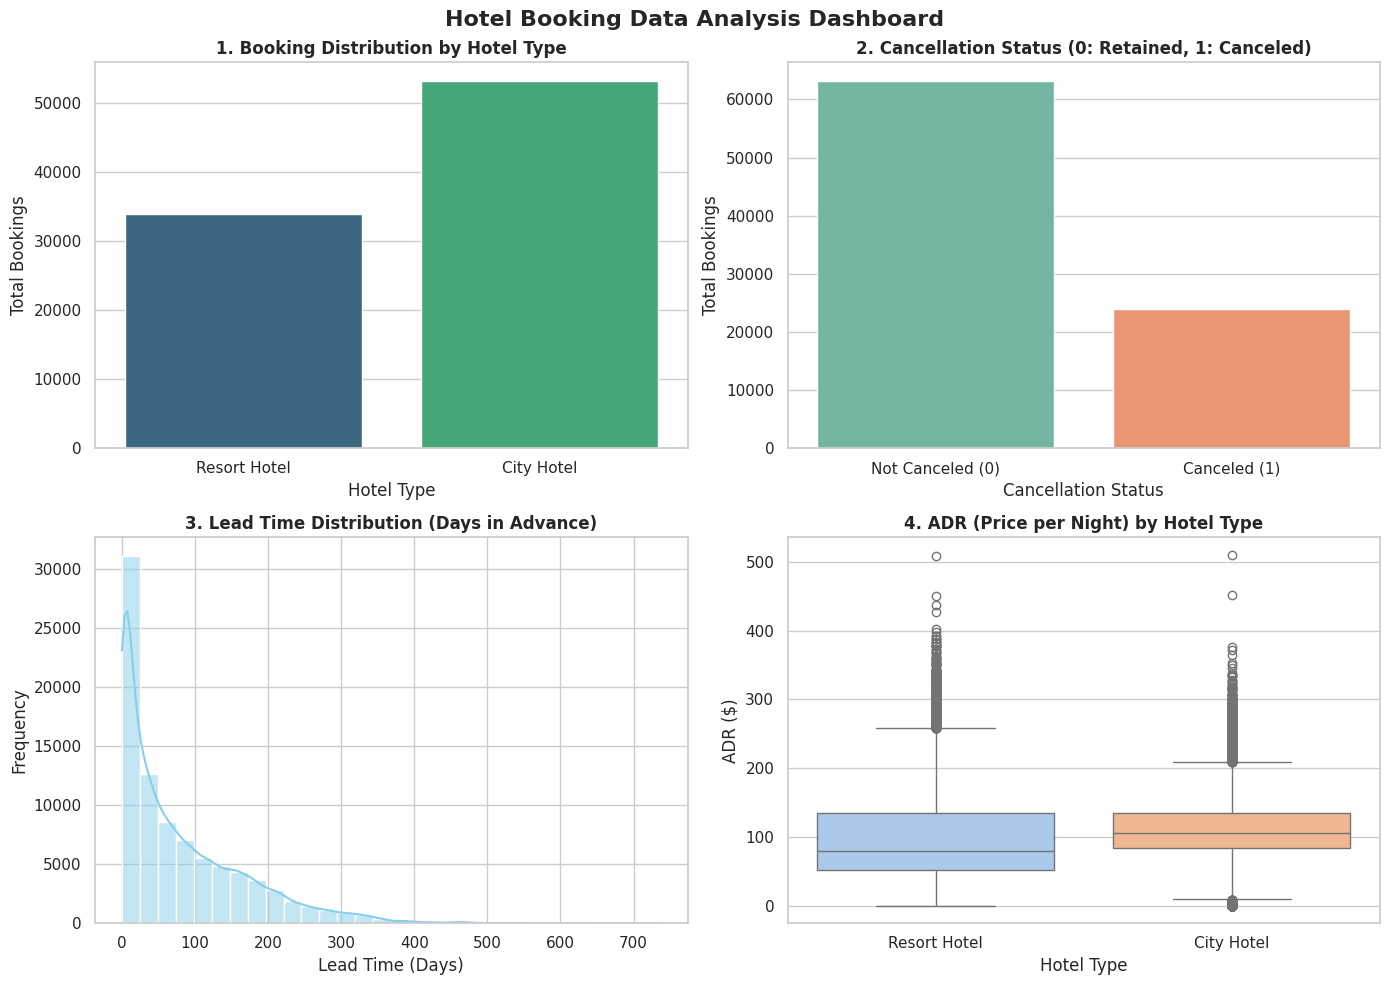

In [11]:
# ==============================================================================
# STEP 1: IMPORT LIBRARIES AND LOAD DATASET
# ==============================================================================
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns

# Set visualization style
sns.set_theme(style="whitegrid")
plt.rcParams['font.size'] = 10

# Load dataset
url = 'https://raw.githubusercontent.com/rfordatascience/tidytuesday/master/data/2020/2020-02-11/hotels.csv'
df_raw = pd.read_csv(url)

print("--- 1. DATASET SUCCESSFULLY LOADED ---")
print(f"Original shape (Rows, Columns): {df_raw.shape}")


# ==============================================================================
# STEP 2: EXPLORATORY DATA ANALYSIS (EDA) & BASIC CHECKS
# ==============================================================================
print("\n--- 2. DATASET SUMMARY & INFORMATION ---")
print(df_raw.info())

print("\n--- 3. MISSING VALUES CHECK ---")
print(df_raw.isnull().sum()[df_raw.isnull().sum() > 0])

print("\n--- 4. DESCRIPTIVE STATISTICS (NUMERICAL COLUMNS) ---")
print(df_raw.describe().T)


# ==============================================================================
# STEP 3: DATA CLEANING & PREPROCESSING
# ==============================================================================
# Create a copy for cleaning to preserve raw data
df_clean = df_raw.copy()

# 1. Remove duplicate rows
df_clean = df_clean.drop_duplicates()

# 2. Handle missing values
df_clean['agent'] = df_clean['agent'].fillna(0)
df_clean['company'] = df_clean['company'].fillna(0)
df_clean['country'] = df_clean['country'].fillna('Unknown')
df_clean['children'] = df_clean['children'].fillna(0)

# 3. Handle outliers & invalid records
# Remove negative ADR values and extreme outliers (> $1000)
df_clean = df_clean[(df_clean['adr'] >= 0) & (df_clean['adr'] <= 1000)]

# Remove records where total guests (adults + children + babies) equals zero
total_guests = df_clean['adults'] + df_clean['children'] + df_clean['babies']
df_clean = df_clean[total_guests > 0]

print("\n--- DATA CLEANING COMPLETED ---")
print(f"Cleaned dataset shape: {df_clean.shape[0]} rows (Filtered from {df_raw.shape[0]})")


# ==============================================================================
# STEP 4: DATA VISUALIZATION (2x2 DASHBOARD)
# ==============================================================================
fig, axes = plt.subplots(2, 2, figsize=(14, 10))
fig.suptitle('Hotel Booking Data Analysis Dashboard', fontsize=16, fontweight='bold')

# Plot 1: Booking Count by Hotel Type
sns.countplot(
    data=df_clean,
    x='hotel',
    hue='hotel',
    legend=False,
    palette='viridis',
    ax=axes[0, 0]
)
axes[0, 0].set_title('1. Booking Distribution by Hotel Type', fontweight='bold')
axes[0, 0].set_xlabel('Hotel Type')
axes[0, 0].set_ylabel('Total Bookings')

# Plot 2: Cancellation Status (0 = Not Canceled, 1 = Canceled)
sns.countplot(
    data=df_clean,
    x='is_canceled',
    hue='is_canceled',
    legend=False,
    palette='Set2',
    ax=axes[0, 1]
)
axes[0, 1].set_title('2. Cancellation Status (0: Retained, 1: Canceled)', fontweight='bold')
axes[0, 1].set_xlabel('Cancellation Status')
axes[0, 1].set_ylabel('Total Bookings')
axes[0, 1].set_xticks([0, 1])
axes[0, 1].set_xticklabels(['Not Canceled (0)', 'Canceled (1)'])

# Plot 3: Lead Time Distribution
sns.histplot(
    data=df_clean,
    x='lead_time',
    bins=30,
    kde=True,
    color='skyblue',
    ax=axes[1, 0]
)
axes[1, 0].set_title('3. Lead Time Distribution (Days in Advance)', fontweight='bold')
axes[1, 0].set_xlabel('Lead Time (Days)')
axes[1, 0].set_ylabel('Frequency')

# Plot 4: Average Daily Rate (ADR) Distribution by Hotel
sns.boxplot(
    data=df_clean,
    x='hotel',
    y='adr',
    hue='hotel',
    legend=False,
    palette='pastel',
    ax=axes[1, 1]
)
axes[1, 1].set_title('4. ADR (Price per Night) by Hotel Type', fontweight='bold')
axes[1, 1].set_xlabel('Hotel Type')
axes[1, 1].set_ylabel('ADR ($)')

# Adjust layout spacing
plt.tight_layout()
plt.show()

## 5. Sensitive Information and Sampling Bias

### Privacy and PII Risks
- **Direct PII:** The dataset does not contain explicit personally identifiable information (PII) such as customer names, phone numbers, email addresses, or credit card details.
- **Quasi-Identifiers:** Quasi-identifiers exist, such as `country`, `agent`, `company`, and `arrival_date`. When combined, these could present mild re-identification risks for high-profile or corporate guests.
- **Handling Strategy:** Mask or generalize agency and corporate IDs into broad categories (e.g., "Third-Party Agent" vs "Direct Booking") and aggregate broad geographic regions to prevent potential re-identification.

### Sampling Bias and Group Imbalance
- **Geographic Skew:** Over 40.8% of total bookings originate from a single country (`PRT` - Portugal). This heavy concentration limits the generalizability of predictive models to global markets outside of Western Europe.
- **Distribution Channel Imbalance:** Online Travel Agents (OTA) dominate the distribution channel entries, causing lower representation of walk-in or offline corporate reservations.
- **Handling Strategy:** Apply stratified sampling based on `hotel` type and geographic zone when splitting the dataset into training and testing sets for machine learning models.

---

## 6. Conclusion

- **Fitness for Purpose:** After executing data profiling and handling issues (imputing `company`, `agent`, and `country`, dropping 180 zero-guest records, removing duplicate entries, and capping extreme ADR outliers), the dataset is fit for diagnosing booking patterns and predicting cancellation risks.
- **Remaining Limitations:**
  1. High missingness in corporate identity attributes (`company` at 94.31%).
  2. Severe geographic skew toward Portuguese and European guests.
  3. Potential bias introduced by unverified duplicate transaction entries.